# Unit 4 · AI-Assisted Visualization — Demo Notebook 2
**Lecture 2: Natural Language & Conversational Visualization** · Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

Everything runs on a **synthetic housing dataset** generated below. The LLM parts use a **mock LLM** (a deterministic function) so the notebook works offline —
everything *around* it (prompts, parsing, validation, state tracking, repair loops) is real, working code.

| # | Topic | What we build |
|---|-------|---------------|
| 1 | Natural Language to Visualization (NL2Vis) | The Parse → Abstract → Specify pipeline, a working mini NL2Vis engine |
| 2 | Query → data/task abstraction → visualization | Cue-word → task table, Munzner's task vocabulary, three worked questions |
| 3 | Semantic parsing & ambiguity | Attribute/value/aggregation/intent detection, Levenshtein matching, parser families, ambiguity strategies |
| 4 | Conversational visualization systems | Architecture with a dialogue state, salient answers |
| 5 | Multi-turn querying & refinement | The seven turn types, a state machine |
| 6 | Follow-ups & context preservation | Ellipsis, anaphora, Continue/Retain/Shift, the 5-turn trace, compounding errors |
| 7 | Text-to-chart with LLMs | Prompting strategies, Generate → Execute → Repair loop, system comparison |
| 8 | LLM-generated chart specifications | Vega-Lite specs, 4-stage validation, EM / EA evaluation |
| 9 | Conversational chart editing | Spec patches, minimal change, assertion titles |
| 10 | Benefits, failure modes, mitigations | Six failure modes, Munzner's nested model, a safe pipeline |

In [1]:
import math, itertools, re, warnings, json, copy, difflib
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30, "display.width", 150, "display.max_colwidth", 80)

In [2]:
# ---------------- mini Vega-Lite-style renderer (do not edit) ----------------
import copy, json, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ACCENT, GREY, BLUE = "#E8710A", "#BDBDBD", "#4C72B0"

def apply_filters(df, spec):
    for t in spec.get("transform", []):
        f = t.get("filter")
        if not f:
            continue
        if "equal" in f:
            df = df[df[f["field"]] == f["equal"]]
        elif "oneOf" in f:
            df = df[df[f["field"]].isin(f["oneOf"])]
    return df

def is_horizontal(spec):
    e = spec["encoding"]
    return spec["mark"] == "bar" and e["x"].get("type") == "quantitative" and e["y"].get("type") in ("nominal", "ordinal")

def compute(spec, df):
    """Return the tidy table that the chart plots (used for drawing AND for checking values)."""
    enc, mark = spec["encoding"], spec["mark"]
    d = apply_filters(df, spec)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        return d[[x["field"], y["field"]] + ([sf] if sf else [])].copy()
    if x.get("bin"):
        return d[[x["field"]]].copy()
    cat, val = (y, x) if is_horizontal(spec) else (x, y)
    agg = val.get("aggregate", "mean")
    keys = [cat["field"]] + ([sf] if sf else [])
    out = d.groupby(keys).size().rename("value") if agg == "count" else d.groupby(keys)[val["field"]].agg(agg).rename("value")
    return out.reset_index()

def _order(labels, field, sort, totals):
    labels = list(dict.fromkeys(labels))
    if sort in ("-y", "-x"):
        return sorted(labels, key=lambda l: -totals[l])
    if sort in ("y", "x"):
        return sorted(labels, key=lambda l: totals[l])
    if field == "month":
        return sorted(labels, key=MONTHS.index)
    return sorted(labels)

def render_spec(spec, df, ax=None, figsize=(6, 3.4)):
    enc, mark = spec["encoding"], spec["mark"]
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    t = compute(spec, df)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        if sf:
            for k, g in t.groupby(sf):
                ax.scatter(g[x["field"]], g[y["field"]], s=10, alpha=.6, label=str(k))
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
        else:
            ax.scatter(t[x["field"]], t[y["field"]], s=10, alpha=.5, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", y["field"]))
    elif x.get("bin"):
        ax.hist(t[x["field"]], bins=25, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", "count"))
    else:
        horiz = is_horizontal(spec)
        cat, val = (y, x) if horiz else (x, y)
        cf = cat["field"]
        tot = t.groupby(cf)["value"].sum()
        labels = _order(t[cf], cf, cat.get("sort"), tot)
        idx = np.arange(len(labels))
        series = sorted(t[sf].unique()) if sf else [None]
        for j, s in enumerate(series):
            g = t if s is None else t[t[sf] == s]
            vals = g.set_index(cf)["value"].reindex(labels).values
            if mark == "bar":
                w = 0.8 / len(series)
                pos = idx + (j - (len(series) - 1) / 2) * w
                colors = BLUE
                cond = c.get("condition")
                if s is None and cond:
                    colors = [ACCENT if l == cond["equal"] else c.get("value", GREY) for l in labels]
                (ax.barh if horiz else ax.bar)(pos, vals, w * 0.95, color=colors, label=None if s is None else str(s))
            else:
                ax.plot(idx, vals, marker="o", ms=3, label=None if s is None else str(s))
        (ax.set_yticks if horiz else ax.set_xticks)(idx)
        (ax.set_yticklabels if horiz else ax.set_xticklabels)(labels, fontsize=8)
        if horiz: ax.invert_yaxis()
        vtitle = val.get("title") or f"{val.get('aggregate', 'mean')}({val['field']})"
        ctitle = cat.get("title") or cat["field"]
        (ax.set_ylabel if not horiz else ax.set_xlabel)(vtitle)
        (ax.set_xlabel if not horiz else ax.set_ylabel)(ctitle)
        sc = val.get("scale", {})
        if sc.get("type") == "log":
            (ax.set_xscale if horiz else ax.set_yscale)("log")
        if mark == "bar" and sc.get("zero") is False:
            lo = t["value"].min() * 0.96
            (ax.set_xlim if horiz else ax.set_ylim)(lo, t["value"].max() * 1.02)
        if sf:
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
    ax.set_title(spec.get("title", ""), fontsize=10, fontweight="bold", loc="left")
    return ax

def show_specs(specs, df, ncols=3, w=4.6, h=3.3):
    n = len(specs); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, s in zip(axes.ravel(), specs):
        ax.axis("on"); render_spec(s, df, ax=ax)
    plt.tight_layout(); plt.show()

## 0 · The synthetic dataset
`housing` — one row per property sale in four Indian cities (prices in ₹ lakh, rent in ₹/month).
Notice there are **two price columns** (`list_price`, `sale_price`): the word *"price"* is genuinely **ambiguous**, which we will exploit later.

In [3]:
rng = np.random.default_rng(11)
n = 1600
cities = ["Pune", "Hyderabad", "Chennai", "Mumbai"]
rate = {"Pune": 7500, "Hyderabad": 6800, "Chennai": 6600, "Mumbai": 16500}      # Rs per sq.ft

city  = rng.choice(cities, n, p=[.28, .27, .25, .20])
year  = rng.choice([2022, 2023, 2024, 2025], n)
month = rng.choice(MONTHS, n)
ptype = rng.choice(["Apartment", "Villa", "Studio"], n, p=[.60, .15, .25])
bedrooms = np.where(ptype == "Studio", 1, rng.integers(1, 5, n))
area = np.where(ptype == "Studio", rng.normal(450, 60, n), bedrooms * rng.normal(520, 70, n) + 300).round(0)
growth   = 1 + 0.07 * (year - 2022)
seasonal = 1 + 0.05 * np.sin(np.array([MONTHS.index(m) for m in month]) / 12 * 2 * np.pi)
sale = area * np.array([rate[c] for c in city]) * growth * seasonal * rng.lognormal(0, .12, n) / 1e5

housing = pd.DataFrame({
    "city": city, "year": year, "month": month, "property_type": ptype, "bedrooms": bedrooms,
    "area_sqft": area, "list_price": (sale * rng.normal(1.06, .03, n)).round(1), "sale_price": sale.round(1),
    "monthly_rent": (sale * 1e5 * 0.0028 * rng.normal(1, .08, n)).round(-2),
})
df = housing
display(df.head())
print(df.groupby("city")["sale_price"].mean().round(1).to_dict())

,city,year,month,property_type,bedrooms,area_sqft,list_price,sale_price,monthly_rent
0,Pune,2025,Feb,Apartment,2,1672.0,176.8,164.2,55700.0
1,Hyderabad,2022,Nov,Studio,1,385.0,24.9,23.3,7800.0
2,Chennai,2025,Oct,Studio,1,525.0,40.0,37.6,10400.0
3,Pune,2024,Nov,Apartment,2,1245.0,99.6,94.7,26400.0
4,Pune,2023,May,Studio,1,547.0,54.2,49.3,13400.0


{'Chennai': 99.7, 'Hyderabad': 99.1, 'Mumbai': 234.2, 'Pune': 109.2}


---
# Topic 1 · Natural Language to Visualization (NL2Vis)
*Natural language lowers the barrier: users say **what they want to know**, and the system decides **how to show it**.*

### 1.1 What is NL2Vis?
> NL2Vis translates a natural-language question about a dataset into a **visualization specification** (fields, transformations, mark, encodings) and renders it.

| Input | Output |
|---|---|
| A question in plain language | A spec (e.g. Vega-Lite JSON) or SQL + chart type |
| The dataset **schema**: column names, types, sample values | The rendered chart |
| Optional: dialogue history | Often a sentence explaining the interpretation |

Examples in the wild: Tableau Ask Data / Pulse, Power BI Q&A and Copilot, the NL4DV toolkit, ChatGPT data analysis, LIDA.

### 1.2 The NL2Vis pipeline: **Parse → Abstract → Specify**
1. **Parse** — find attributes, values, aggregations and words that signal a task.
2. **Abstract** — turn domain words into generic data types and an abstract task (Munzner Ch 2–3).
3. **Specify** — choose mark and channels (Deck 1 rules), then render and explain.

We build this pipeline step by step over the next topics. First, the *inputs*: the schema a parser sees.

In [4]:
def schema_of(df, n_samples=3):
    rows = []
    for c in df.columns:
        kind = "quantitative" if pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 6 else ("ordinal" if c in ("year", "month", "bedrooms") else "nominal")
        rows.append((c, str(df[c].dtype), kind, df[c].nunique(), ", ".join(map(str, df[c].drop_duplicates().head(n_samples)))))
    return pd.DataFrame(rows, columns=["column", "dtype", "abstract type", "#unique", "sample values"])
schema_of(df)

,column,dtype,abstract type,#unique,sample values
0,city,str,nominal,4,"Pune, Hyderabad, Chennai"
1,year,int64,ordinal,4,"2025, 2022, 2024"
2,month,str,ordinal,12,"Feb, Nov, Oct"
3,property_type,str,nominal,3,"Apartment, Studio, Villa"
4,bedrooms,int64,ordinal,4,"2, 1, 3"
5,area_sqft,float64,quantitative,1080,"1672.0, 385.0, 525.0"
6,list_price,float64,quantitative,1170,"176.8, 24.9, 40.0"
7,sale_price,float64,quantitative,1135,"164.2, 23.3, 37.6"
8,monthly_rent,float64,quantitative,650,"55700.0, 7800.0, 10400.0"


---
# Topic 2 · Query → Data/Task Abstraction → Visualization
### 2.1 Why translate queries into *abstract* tasks?
Two domain experts, very different words:
* *Epidemiologist:* "Contrast the prognosis of patients intubated in the ICU more than one month after exposure to patients hospitalized within the first week"
* *Biologist:* "See if the results for the tissue samples treated with LL-37 match up with the ones without the peptide"

**Same abstract task:** *compare values between two groups.* In NL2Vis, different words (*contrast, match up, vs, compared with*) must map to **one** abstract task.

In [5]:
TASK_PARAPHRASES = {
    "compare values": ["contrast", "match up", "vs", "versus", "compared with", "across", "differ between"],
    "trend":          ["over time", "trend", "since", "monthly", "change over", "evolve"],
    "distribution":   ["distribution", "spread", "range", "how varied"],
}
def abstract_task_of(text):
    t = text.lower()
    for task, cues in TASK_PARAPHRASES.items():
        if any(re.search(rf"\b{re.escape(c)}\b", t) for c in cues):
            return task
    return "unknown -> ask the user"

for q in ["Contrast the prognosis of ICU patients with early-hospitalised patients",
          "See if treated samples match up with the untreated ones",
          "Pune vs Chennai price", "How did the price evolve?", "How varied are prices?"]:
    print(f"{q[:62]:64s} -> {abstract_task_of(q)}")

Contrast the prognosis of ICU patients with early-hospitalised   -> compare values
See if treated samples match up with the untreated ones          -> compare values
Pune vs Chennai price                                            -> compare values
How did the price evolve?                                        -> trend
How varied are prices?                                           -> distribution


### 2.2 Munzner's task vocabulary: actions and targets

In [6]:
pd.DataFrame([
    ("Analyze",              "discover (generate / verify hypothesis), present, enjoy",             "explore, show me, is it true that ..."),
    ("Search",               "lookup (target & location known), locate (target known), browse (location known), explore (neither known)", "find, where is, look at, anything interesting"),
    ("Query",                "identify one · compare some · summarize all",                           "what is, compare, vs, overall, summary"),
    ("Targets (all data)",   "trends, outliers, features",                                            "over time, trend, unusual, spikes"),
    ("Targets (attributes)", "one value, extremes, distribution; dependency, correlation, similarity", "highest, top 5, spread, related to, correlated"),
], columns=["Level", "Abstract terms", "Typical words in a query"]).set_index("Level")

,Abstract terms,Typical words in a query
Level,,
Analyze,"discover (generate / verify hypothesis), present, enjoy","explore, show me, is it true that ..."
Search,"lookup (target & location known), locate (target known), browse (location kn...","find, where is, look at, anything interesting"
Query,identify one · compare some · summarize all,"what is, compare, vs, overall, summary"
Targets (all data),"trends, outliers, features","over time, trend, unusual, spikes"
Targets (attributes),"one value, extremes, distribution; dependency, correlation, similarity","highest, top 5, spread, related to, correlated"


In [7]:
def search_mode(target_known, location_known):
    # Munzner 3.1: both known -> lookup; target known, location unknown -> locate; location known -> browse; neither -> explore
    if target_known and location_known: return "lookup"
    if target_known:                    return "locate"
    if location_known:                  return "browse"
    return "explore"

for tk, lk, ex in [(True, True, "What is Pune's mean price in 2024?"), (True, False, "Where is the cheapest city?"),
                   (False, True, "Look at the Mumbai listings"), (False, False, "Anything interesting in the data?")]:
    print(f"target known={tk!s:5}  location known={lk!s:5} -> {search_mode(tk, lk):8s} | {ex}")

target known=True   location known=True  -> lookup   | What is Pune's mean price in 2024?
target known=True   location known=False -> locate   | Where is the cheapest city?
target known=False  location known=True  -> browse   | Look at the Mumbai listings
target known=False  location known=False -> explore  | Anything interesting in the data?


### 2.3 From words to tasks to charts (cue-word table)
Knaflic Ch 2: prefer simple text, tables, lines and bars; avoid pies with many slices, 3D and secondary y-axes.

In [8]:
CUE_TABLE = [   # (task, cue phrases, default chart)  -- priority order: first match wins
    ("trend",          ["over time", "trend", "since", "monthly", "by month", "over the last", "change", "changed", "yearly"], "Line chart"),
    ("extremes",       ["top", "highest", "lowest", "best", "worst", "cheapest", "most expensive"],                          "Sorted bar, top-k highlighted"),
    ("distribution",   ["distribution", "spread", "range", "how varied"],                                                    "Histogram / boxplot"),
    ("correlation",    ["related to", "correlation", "depends on", "relationship"],                                         "Scatter plot"),
    ("part-to-whole",  ["share", "percentage of", "breakdown", "proportion"],                                                "Stacked bar / pie (few parts)"),
    ("outliers",       ["unusual", "outlier", "anomaly", "spike"],                                                           "Scatter / line with highlights"),
    ("compare",        ["compare", "vs", "versus", "across", "between", "by"],                                               "Sorted bar chart"),
]
display(pd.DataFrame([(t, ", ".join(c), ch) for t, c, ch in CUE_TABLE], columns=["Abstract task", "Cue words in the query", "Default chart"]).set_index("Abstract task"))

def detect_task(q):
    q = q.lower()
    for task, cues, chart in CUE_TABLE:
        if any(re.search(rf"\b{re.escape(c)}\b", q) for c in cues):
            return task, chart
    return None, None

,Cue words in the query,Default chart
Abstract task,,
trend,"over time, trend, since, monthly, by month, over the last, change, changed, ...",Line chart
extremes,"top, highest, lowest, best, worst, cheapest, most expensive","Sorted bar, top-k highlighted"
distribution,"distribution, spread, range, how varied",Histogram / boxplot
correlation,"related to, correlation, depends on, relationship",Scatter plot
part-to-whole,"share, percentage of, breakdown, proportion",Stacked bar / pie (few parts)
outliers,"unusual, outlier, anomaly, spike",Scatter / line with highlights
compare,"compare, vs, versus, across, between, by",Sorted bar chart


### 2.4 Worked example: three questions, three abstractions

In [9]:
examples = [("How did sale price change over 2024?",      "month (ordinal), sale_price (Q)", ),
            ("Compare average price across cities",       "city (N), mean price (Q)"),
            ("Is price related to flat size?",            "area_sqft (Q), price (Q)")]
pd.DataFrame([(q, d, *detect_task(q)) for q, d in examples], columns=["Query", "Data abstraction", "Task", "Chart"])

,Query,Data abstraction,Task,Chart
0,How did sale price change over 2024?,"month (ordinal), sale_price (Q)",trend,Line chart
1,Compare average price across cities,"city (N), mean price (Q)",compare,Sorted bar chart
2,Is price related to flat size?,"area_sqft (Q), price (Q)",correlation,Scatter plot


---
# Topic 3 · Semantic Parsing of User Intent
### 3.1 From sentence to specification
Sub-tasks of a semantic parser: **attribute detection** (words → columns, with synonyms) · **value detection** (*'Pune'*, *'2024'* → filters) ·
**aggregation** (average, total, count) · **task / intent** (compare, trend, correlation) · **explicit chart words** (*'as a bar chart'*).

Target output (NL4DV-style analytic spec):
```json
{"attributes": ["price","city"], "filters": [{"year": 2024}], "aggregate": {"price": "mean"},
 "task": "compare", "vis": {"mark": "bar", "x": "city", "y": "mean(price)"}}
```
First, the text-matching primitive for **misspelt attributes**: Levenshtein (edit) distance.

In [10]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def similarity(a, b):
    return 1 - levenshtein(a, b) / max(len(a), len(b))

### Numerical 1 · Matching a misspelt attribute
Query: *"show avg **revnue** by month"*. Columns: revenue, review, reserve, region, returns. Match the column with the highest similarity **if ≥ 0.7**; otherwise **ask, don't guess**.

In [11]:
def match_column(token, columns, threshold=0.7):
    scored = sorted(((similarity(token, c), c) for c in columns), reverse=True)
    return (scored[0][1] if scored[0][0] >= threshold else None), scored

columns = ["revenue", "review", "reserve", "region", "returns"]
best, scored = match_column("revnue", columns)
pd.DataFrame([(c, len(c), levenshtein("revnue", c), f"1 - {levenshtein('revnue', c)}/{max(len('revnue'), len(c))} = {s:.3f}") for s, c in scored],
             columns=["column", "length", "d(revnue, .)", "similarity"])

,column,length,"d(revnue, .)",similarity
0,revenue,7,1,1 - 1/7 = 0.857
1,review,6,3,1 - 3/6 = 0.500
2,reserve,7,4,1 - 4/7 = 0.429
3,region,6,4,1 - 4/6 = 0.333
4,returns,7,5,1 - 5/7 = 0.286


In [12]:
print("Matched column:", best)                                    # revenue (0.857)
print("Typo 'zzzz'  ->", match_column("zzzz", columns)[0], " -> the system should ASK the user")
print("MCQ 3 check: matches 'revenue' (0.857 >= 0.7); review 0.50 and reserve 0.43 fall below.")

Matched column: revenue
Typo 'zzzz'  -> None  -> the system should ASK the user
MCQ 3 check: matches 'revenue' (0.857 >= 0.7); review 0.50 and reserve 0.43 fall below.


### 3.2 A working mini semantic parser
We now assemble a rule/grammar-based NL2Vis parser (in the spirit of NL4DV / Eviza). It has a **lexicon** (column names + synonyms),
**value detection**, **aggregation words**, the **cue table** from Topic 2, and fuzzy matching for typos.

In [13]:
YEARS = sorted(df.year.unique().tolist())
CAT_COLS, TIME_COLS = ["city", "property_type", "bedrooms"], ["year", "month"]
VALUES_FLAT = {str(v).lower(): (c, v) for c in CAT_COLS for v in df[c].unique()}

SYN = {  # lexicon: word -> candidate columns
    "price": ["sale_price", "list_price"], "cost": ["sale_price"], "sale": ["sale_price"], "list": ["list_price"], "listing": ["list_price"],
    "rent": ["monthly_rent"], "size": ["area_sqft"], "area": ["area_sqft"], "sqft": ["area_sqft"],
    "bedrooms": ["bedrooms"], "bhk": ["bedrooms"], "city": ["city"], "cities": ["city"], "type": ["property_type"], "property": ["property_type"],
    "sale_price": ["sale_price"], "list_price": ["list_price"], "monthly_rent": ["monthly_rent"], "area_sqft": ["area_sqft"], "property_type": ["property_type"],
}
AGG = {"average": "mean", "avg": "mean", "mean": "mean", "total": "sum", "sum": "sum", "median": "median", "count": "count",
       "number": "count", "max": "max", "min": "min"}
CHART_WORDS = {"bar": "bar", "line": "line", "scatter": "point", "histogram": "histogram", "pie": "pie", "chart": None, "plot": None, "graph": None}
STOP = set("show me the a an of for in on by to and or is are was were what how did do does it them their this that with as from at per each all "
           "which who whose there give draw display tell flat flats home homes about now only just instead also".split())
CUE_TOKENS = {w for _, cues, _ in CUE_TABLE for c in cues for w in c.split()}

def lookup(tok):
    return SYN.get(tok) or SYN.get(tok.rstrip("s"))

def parse(query, df=df):
    q = query.lower(); toks = re.findall(r"[a-z0-9_]+", q)
    A = dict(query=query, attributes=[], filters={}, aggregate=None, task=None, mark=None, measure=None, time=None,
             notes=[], ambiguities=[], fuzzy=[], unknown=[])
    # ---- value detection: years and categorical values -------------------------------------------------------
    m1, m2 = re.search(r"last (\d+) years", q), re.search(r"since (\d{4})", q)
    if m1:   A["filters"]["year"] = [y for y in YEARS if y > max(YEARS) - int(m1.group(1))]
    elif m2: A["filters"]["year"] = [y for y in YEARS if y >= int(m2.group(1))]
    else:
        ys = [int(t) for t in toks if t.isdigit() and int(t) in YEARS]
        if ys: A["filters"]["year"] = ys
    found = []
    for t in toks:
        if t.isdigit() or t in STOP or t in CUE_TOKENS or t in CHART_WORDS: continue
        if t in AGG: A["aggregate"] = AGG[t]; continue
        if t in VALUES_FLAT:
            f, v = VALUES_FLAT[t]; A["filters"].setdefault(f, [])
            if v not in A["filters"][f]: A["filters"][f].append(v)
            continue
        cands = lookup(t)
        if cands is None and len(t) >= 4:                                   # ---- fuzzy match for typos
            key, s = max(((k, similarity(t, k)) for k in SYN), key=lambda z: z[1])
            if s >= 0.7: cands = SYN[key]; A["fuzzy"].append((t, key, round(s, 2)))
        if cands is None: A["unknown"].append(t); continue
        found.append(("col", cands[0]) if len(cands) == 1 else ("amb", t, cands))
    # ---- attribute detection with ambiguity resolution ---------------------------------------------------------
    pinned = {x[1] for x in found if x[0] == "col"}
    for x in found:
        if x[0] == "col": col = x[1]
        else:
            _, t, cands = x; hit = [c for c in cands if c in pinned]
            col = hit[0] if hit else cands[0]
            if not hit: A["ambiguities"].append({"type": "Data", "word": t, "candidates": cands, "chosen": col})
        if col not in A["attributes"]: A["attributes"].append(col)
    # ---- aggregation, task, explicit chart ---------------------------------------------------------------------
    A["task"], _ = detect_task(q)
    cw = re.search(r"\b(bar|line|scatter|histogram|pie)\b", q)
    if cw: A["mark"] = CHART_WORDS[cw.group(1)]
    quant = [c for c in A["attributes"] if c not in CAT_COLS + TIME_COLS]
    A["measure"] = quant[0] if quant else None
    if re.search(r"\bmonth(ly|s)?\b", q): A["time"] = "month"
    elif "year" in q:                      A["time"] = "year"
    elif len(A["filters"].get("year", [])) == 1: A["time"] = "month"
    else: A["time"] = "year"
    if A["task"] is None:
        A["task"] = "correlation" if len(quant) >= 2 else ("compare" if A["measure"] and any(c in CAT_COLS for c in A["attributes"]) else ("distribution" if A["measure"] else None))
        if A["task"]: A["notes"].append(f"no task words -> inferred '{A['task']}' from data types")
    if A["measure"] and A["task"] in ("compare", "extremes", "part-to-whole", "trend") and A["aggregate"] is None:
        A["aggregate"] = "mean"; A["ambiguities"].append({"type": "Aggregation", "word": "(none stated)", "candidates": ["mean", "sum"], "chosen": "mean"})
    return A

A = parse("average price by city in 2024")
print(json.dumps({k: A[k] for k in ["attributes", "filters", "aggregate", "task", "measure", "ambiguities"]}, indent=1, default=str))

{
 "attributes": [
  "sale_price",
  "city"
 ],
 "filters": {
  "year": [
   2024
  ]
 },
 "aggregate": "mean",
 "task": "compare",
 "measure": "sale_price",
 "ambiguities": [
  {
   "type": "Data",
   "word": "price",
   "candidates": [
    "sale_price",
    "list_price"
   ],
   "chosen": "sale_price"
  }
 ]
}


Q: 'average price by city in 2024'
   Interpretation: mean(sale_price) by city · filters: year = 2024 · bar chart
   ! Data ambiguity: 'price' -> chose 'sale_price' among ['sale_price', 'list_price']


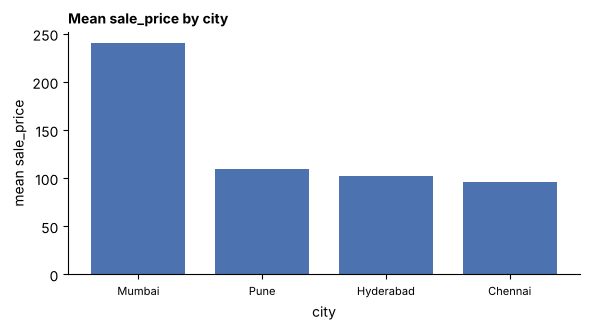

In [14]:
@dataclass
class State:
    measure: str = None
    agg: str = "mean"
    x: str = None
    color: str = None
    filters: dict = field(default_factory=dict)
    mark: str = "bar"
    sort: str = None
    recent: dict = field(default_factory=dict)       # last replaced filter values, for "compare the two"

def build_state(A):
    task, meas = A["task"], A["measure"]
    cats = [c for c in A["attributes"] if c in CAT_COLS]
    multi = [f for f, v in A["filters"].items() if f in CAT_COLS and len(v) > 1]
    group = cats[0] if cats else (multi[0] if multi else None)
    if task == "trend" and meas:
        return State(meas, A["aggregate"] or "mean", A["time"], group if group != A["time"] else None, dict(A["filters"]), A["mark"] or "line")
    if task in ("compare", "extremes", "part-to-whole") and meas and group:
        return State(meas, A["aggregate"] or "mean", group, None, dict(A["filters"]), A["mark"] or "bar", "-y")
    if task == "correlation" and len([c for c in A["attributes"] if c not in CAT_COLS + TIME_COLS]) >= 2:
        q = [c for c in A["attributes"] if c not in CAT_COLS + TIME_COLS]
        return State(q[0], None, q[1], group, dict(A["filters"]), "point")   # first-mentioned = y (dependent), second = x
    if task == "distribution" and meas:
        return State(meas, "count", meas, None, dict(A["filters"]), "histogram")
    return None

def vl_type(col): return "nominal" if col in CAT_COLS else ("ordinal" if col in TIME_COLS else "quantitative")

def state_to_spec(s, title=None):
    tr = [{"filter": {"field": f, **({"equal": v[0]} if len(v) == 1 else {"oneOf": list(v)})}} for f, v in s.filters.items()]
    if s.mark == "point":
        enc = {"x": {"field": s.x, "type": "quantitative"}, "y": {"field": s.measure, "type": "quantitative", "title": s.measure}}
    elif s.mark == "histogram":
        enc = {"x": {"field": s.measure, "type": "quantitative", "bin": True}, "y": {"aggregate": "count", "type": "quantitative", "title": "count"}}
    else:
        enc = {"x": {"field": s.x, "type": vl_type(s.x), **({"sort": s.sort} if s.sort and s.mark == "bar" else {})},
               "y": {"field": s.measure, "aggregate": s.agg, "type": "quantitative", "title": f"{s.agg} {s.measure}"}}
    if s.color: enc["color"] = {"field": s.color, "type": vl_type(s.color)}
    mark = "bar" if s.mark == "histogram" else s.mark
    auto = f"{s.agg or ''} {s.measure} by {s.x}".strip().capitalize()
    return {"title": title or auto, "transform": tr, "mark": mark, "encoding": enc}

def describe(s):
    flt = ", ".join(f"{f} = {v[0] if len(v) == 1 else v}" for f, v in s.filters.items()) or "none"
    what = f"{s.agg}({s.measure})" if s.agg else s.measure
    return f"{what} by {s.x}{' / colour = ' + s.color if s.color else ''} · filters: {flt} · {s.mark} chart"

def nl2vis(query, df=df, show=True):
    A = parse(query, df); s = build_state(A)
    print(f"Q: {query!r}")
    if s is None:
        print("   -> Could not build a chart (no measure/group/task recognised). ASK THE USER."); return A, None, None
    print("   Interpretation:", describe(s))
    for a in A["ambiguities"]: print(f"   ! {a['type']} ambiguity: {a['word']!r} -> chose {a['chosen']!r} among {a['candidates']}")
    for w, k, sc in A["fuzzy"]: print(f"   ~ fuzzy match: {w!r} -> {k!r} (similarity {sc})")
    spec = state_to_spec(s)
    if show: render_spec(spec, df); plt.tight_layout(); plt.show()
    return A, s, spec

_ = nl2vis("average price by city in 2024")

**Slide 7, "Parsing a query":** *average* → aggregation = mean · *price* → quantitative attribute (**ambiguous**: two price columns) · *city* → categorical · *2024* → filter on `year` ·
implicit task **compare** → **sorted bar chart**. The system *echoes its interpretation* so the user can catch mistakes.

### 3.3 Three questions, three charts (+ a typo and an explicit chart word)

Q: 'How did sale price change over 2024?'
   Interpretation: mean(sale_price) by month · filters: year = 2024 · line chart
   ! Aggregation ambiguity: '(none stated)' -> chose 'mean' among ['mean', 'sum']
Q: 'Compare average price across cities'
   Interpretation: mean(sale_price) by city · filters: none · bar chart
   ! Data ambiguity: 'price' -> chose 'sale_price' among ['sale_price', 'list_price']
Q: 'Is sale price related to flat size?'
   Interpretation: sale_price by area_sqft · filters: none · point chart


Q: 'Show avg prise by property type as a line chart'
   Interpretation: mean(sale_price) by property_type · filters: none · line chart
   ! Data ambiguity: 'prise' -> chose 'sale_price' among ['sale_price', 'list_price']
   ~ fuzzy match: 'prise' -> 'price' (similarity 0.8)


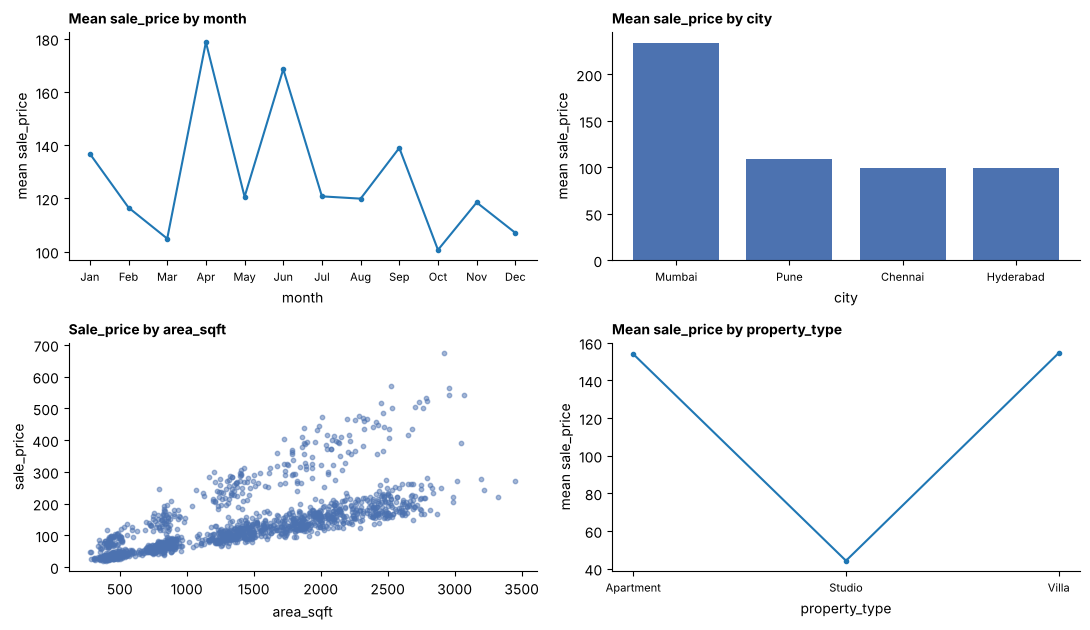

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for ax, q in zip(axes.ravel(), ["How did sale price change over 2024?", "Compare average price across cities",
                                "Is sale price related to flat size?", "Show avg prise by property type as a line chart"]):
    A, s, spec = nl2vis(q, show=False)
    if spec: render_spec(spec, df, ax=ax)
plt.tight_layout(); plt.show()

Note the last query: *"prise"* was **fuzzy-matched** to *price*, and the user's explicit *"line chart"* overrode the default — even though lines across unordered categories are a poor choice
(we will see this as a **failure mode** in Topic 10).

### 3.4 Three families of NL2Vis parsers

In [16]:
pd.DataFrame({
    "": ["How it works", "Examples", "Strengths", "Weaknesses", "Typical output"],
    "Rule / grammar-based": ["Lexicon + dependency parse + hand rules", "Eviza, NL4DV, DataTone", "Predictable, explainable, fast", "Brittle to new phrasing", "Analytic spec (JSON)"],
    "Neural (seq2seq)":     ["Trained on (question, spec) pairs", "Seq2Vis, ncNet (nvBench)", "Learns paraphrases", "Needs large labelled data", "Vega-Lite / VQL"],
    "LLM prompting":        ["Prompt with schema + question; LLM writes spec/code", "Chat2VIS, LIDA, Copilot", "Handles open-ended, messy language", "Hallucinates fields; non-deterministic", "Python code or Vega-Lite"],
}).set_index("")

,Rule / grammar-based,Neural (seq2seq),LLM prompting
,,,
How it works,Lexicon + dependency parse + hand rules,"Trained on (question, spec) pairs",Prompt with schema + question; LLM writes spec/code
Examples,"Eviza, NL4DV, DataTone","Seq2Vis, ncNet (nvBench)","Chat2VIS, LIDA, Copilot"
Strengths,"Predictable, explainable, fast",Learns paraphrases,"Handles open-ended, messy language"
Weaknesses,Brittle to new phrasing,Needs large labelled data,Hallucinates fields; non-deterministic
Typical output,Analytic spec (JSON),Vega-Lite / VQL,Python code or Vega-Lite


Q: 'typical value of homes per town'
   -> Could not build a chart (no measure/group/task recognised). ASK THE USER.
Q: 'average price by city'
   Interpretation: mean(sale_price) by city · filters: none · bar chart
   ! Data ambiguity: 'price' -> chose 'sale_price' among ['sale_price', 'list_price']


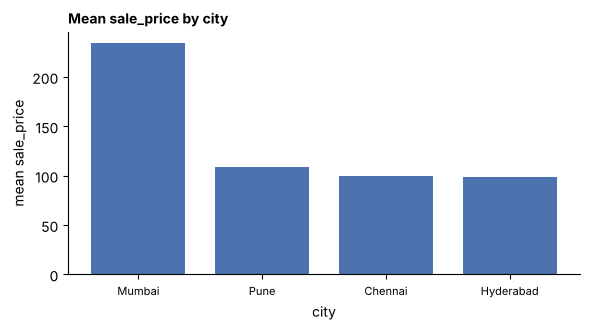


Trend: HYBRID systems -> LLM for language understanding, rules and validators for safe chart specs.


In [17]:
# Brittleness of the rule-based parser: a paraphrase it has no lexicon entry for
nl2vis("typical value of homes per town")
nl2vis("average price by city")
print("\nTrend: HYBRID systems -> LLM for language understanding, rules and validators for safe chart specs.")

### 3.5 Ambiguity in natural-language queries
| Type | Example |
|---|---|
| Data | which column is *'price'*? |
| Value | what counts as *'top'*? |
| Aggregation | average or total? |
| Task | *'show sales'* → trend or compare? |
| Under-specified | no chart named |

Three strategies — each with a trade-off:

In [18]:
pd.DataFrame([("Default + show interpretation", "Pick most likely, state it in text", "Fast; user must notice errors"),
              ("Ambiguity widget",              "Dropdowns for each uncertain choice", "Transparent; slightly more UI"),
              ("Clarifying question",           "'Did you mean list or sale price?'", "Accurate; slows the user")],
             columns=["Strategy", "How", "Trade-off"]).set_index("Strategy")

,How,Trade-off
Strategy,,
Default + show interpretation,"Pick most likely, state it in text",Fast; user must notice errors
Ambiguity widget,Dropdowns for each uncertain choice,Transparent; slightly more UI
Clarifying question,'Did you mean list or sale price?',Accurate; slows the user


In [19]:
def handle_ambiguity(query, strategy):
    A = parse(query); s = build_state(A)
    amb = A["ambiguities"]
    if not amb:
        return "No ambiguity -> just draw: " + describe(s)
    if strategy == "default":
        return "Default + echo -> " + describe(s) + "   (silently chose: " + ", ".join(f"{a['word']}->{a['chosen']}" for a in amb) + ")"
    if strategy == "widget":
        return "Widget -> " + " | ".join(f"[{a['type']}: {a['word']!r} v {a['candidates']}]" for a in amb)
    if strategy == "clarify":
        a = amb[0]
        return f"Clarify -> 'Did you mean {' or '.join(a['candidates'])}?'" + ("" if a["type"] == "Data" else "  (aggregation: " + " or ".join(a["candidates"]) + "?)")

for st in ["default", "widget", "clarify"]:
    print(f"{st:8s}:", handle_ambiguity("show price by city", st))

default : Default + echo -> mean(sale_price) by city · filters: none · bar chart   (silently chose: price->sale_price, (none stated)->mean)
widget  : Widget -> [Data: 'price' v ['sale_price', 'list_price']] | [Aggregation: '(none stated)' v ['mean', 'sum']]
clarify : Clarify -> 'Did you mean sale_price or list_price?'


---
# Topic 4 · Conversational Visualization Systems
A conversational visualization system lets users ask a **sequence of related questions**; each turn updates the chart using the **context** of earlier turns.

| System | Year | Key idea |
|---|---|---|
| Eviza (Tableau Research) | 2016 | NL interface with pragmatics for follow-up questions; ambiguity widgets |
| Evizeon | 2018 | Context transitions (continue / retain / shift) across turns |
| Orko | 2018 | Multimodal: speech + touch on network visualizations |
| Tableau Pulse, Power BI Copilot | 2023+ | Chat panels in BI tools; chart + narrative answers |
| Data Formulator 2 | 2024+ | Iterative chart authoring with an LLM, keeps a history of versions |

### 4.1 Architecture: the key new component is the **dialogue state**
Without it, every follow-up would be treated as a brand-new question.

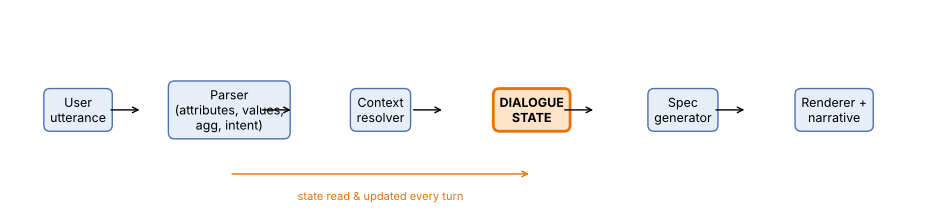

In [20]:
fig, ax = plt.subplots(figsize=(12, 2.6)); ax.axis("off")
boxes = ["User\nutterance", "Parser\n(attributes, values,\nagg, intent)", "Context\nresolver", "DIALOGUE\nSTATE", "Spec\ngenerator", "Renderer +\nnarrative"]
for i, b in enumerate(boxes):
    hot = b.startswith("DIALOGUE")
    ax.text(i * 2.0 + 0.9, 0.5, b, ha="center", va="center", fontsize=9, fontweight="bold" if hot else None,
            bbox=dict(boxstyle="round,pad=0.5", fc="#FDE3C8" if hot else "#E8EEF7", ec="#E8710A" if hot else "#4C72B0", lw=2 if hot else 1))
    if i < len(boxes) - 1: ax.annotate("", xy=(i * 2.0 + 1.75, 0.5), xytext=(i * 2.0 + 1.3 + .0, 0.5), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(6.9, 0.18), xytext=(2.9, 0.18), arrowprops=dict(arrowstyle="->", color="#E8710A", connectionstyle="arc3,rad=0"))
ax.text(4.9, 0.05, "state read & updated every turn", color="#E8710A", ha="center", fontsize=8)
ax.set_xlim(0, 12.3); ax.set_ylim(0, 1); plt.show()

### 4.2 Responses must make the answer **salient** (Ware Ch 5 & 12, Knaflic Ch 4)
Design rules: *one accent colour for the answer, grey for context* · annotate the answer in words · avoid rainbow palettes (every bar competes).
Pre-attentive cues are found **without search**, cutting the cost of the viewer's visual query.

Question: *"Which city has the lowest mean sale price?"*

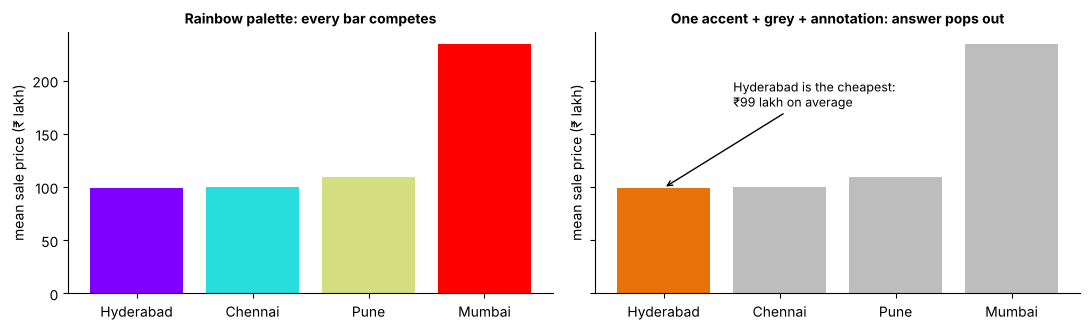

In [21]:
g = df.groupby("city")["sale_price"].mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
ax[0].bar(g.index, g.values, color=plt.cm.rainbow(np.linspace(0, 1, len(g))))
ax[0].set_title("Rainbow palette: every bar competes")
cols = [ACCENT if c == g.index[0] else GREY for c in g.index]
ax[1].bar(g.index, g.values, color=cols)
ax[1].annotate(f"{g.index[0]} is the cheapest:\n₹{g.iloc[0]:.0f} lakh on average", xy=(0, g.iloc[0]), xytext=(0.6, g.max() * .75),
               arrowprops=dict(arrowstyle="->"), fontsize=9)
ax[1].set_title("One accent + grey + annotation: answer pops out")
for a in ax: a.set_ylabel("mean sale price (₹ lakh)")
plt.tight_layout(); plt.show()

---
# Topic 5 · Multi-Turn Querying and Refinement
Munzner §3.2: complex activities are *"a chained sequence of tasks, where the output of one becomes the input to the next."*

| Turn type | Example utterance | What changes in the state |
|---|---|---|
| Refine (filter) | "only for Pune and Mumbai" | add filter; keep fields and chart |
| Elaborate (add field) | "split it by property type" | add colour / facet encoding |
| Change aggregation | "show the median instead" | aggregate mean → median |
| Change view | "as a line chart" | mark bar → line |
| Drill down | "break the year into months" | finer time unit |
| Compare | "and how does that compare with 2023?" | add year as colour / second series |
| Shift / reset | "now show monthly rent by property type" | new measure; drop old filters |

### 5.1 A state machine that applies these turns

In [22]:
def converse(s, utt, df=df):
    u = utt.lower(); P = parse(utt, df)
    new_query = bool(re.search(r"\b(now show|new question)\b", u)) and P["measure"]
    if new_query:
        ns = build_state(P)
        return (ns, ["Shift / reset"], "Shift", ["new topic -> filters and fields reset"]) if ns else (s, ["(not understood)"], "-", ["could not parse -> ask the user"])
    ns = copy.deepcopy(s); ops, notes, transition = [], [], "Continue"
    ask_swap = bool(re.search(r"what about|how about", u))

    if re.search(r"compare (the two|them|both)", u):
        if s.recent:
            ns.filters[s.recent["field"]] = s.recent["values"]; ns.color = s.recent["field"]; ops.append("Compare")
    if re.search(r"\binstead\b", u) and P["aggregate"]:
        ns.agg = P["aggregate"]; ops.append("Change aggregation")
    cw = re.search(r"\b(line|bar|scatter)\b", u)
    if cw: ns.mark = CHART_WORDS[cw.group(1)]; ops.append("Change view")
    if re.search(r"\bsort\b", u): ns.sort = "-y"; ops.append("Sort (anaphora: 'them' = the bars shown)")
    new_cats = [c for c in P["attributes"] if c in CAT_COLS and c != ns.x]
    if re.search(r"\b(split|break|by)\b", u) and new_cats:
        ns.color = new_cats[0]; ops.append("Elaborate")
    if re.search(r"\bmonth(ly|s)?\b", u):
        ns.x, ns.mark, ns.sort = "month", "line", None; ops.append("Drill down")
    for f, vals in P["filters"].items():
        if f in ns.filters and ns.filters[f] != vals:
            old = ns.filters[f]; ns.filters[f] = vals; ns.recent = {"field": f, "values": old + [v for v in vals if v not in old]}
            ops.append("Refine (replace value)"); transition = "Retain" if ask_swap else "Continue"
            notes.append(f"AMBIGOUS: replaced {f} = {old} with {vals}. Say 'add {vals[0]}' to keep both.")
        elif f not in ns.filters:
            ns.filters[f] = vals; ops.append("Refine (add filter)")
    if P["measure"] and P["measure"] != ns.measure and not ops:
        ns.measure = P["measure"]; ops.append("Retain (swap measure)"); transition = "Retain"
    if not ops: return s, ["(not understood)"], "-", ["could not interpret -> ask the user"]
    return ns, ops, transition, notes

def run_dialogue(utterances, show=True):
    A = parse(utterances[0]); s = build_state(A); rows = [(1, utterances[0], "New query", "-", describe(s))]
    states = [s]
    for i, u in enumerate(utterances[1:], 2):
        s, ops, tr, notes = converse(s, u); states.append(s)
        rows.append((i, u, " + ".join(ops), tr, describe(s) + ("   | " + " ".join(notes) if notes else "")))
    return pd.DataFrame(rows, columns=["turn", "utterance", "turn type", "transition", "echoed interpretation"]), states

trace, states = run_dialogue(["average price by city", "only 2024", "show it monthly for Pune", "what about Chennai?", "compare the two"])
trace

,turn,utterance,turn type,transition,echoed interpretation
0,1,average price by city,New query,-,mean(sale_price) by city · filters: none · bar chart
1,2,only 2024,Refine (add filter),Continue,mean(sale_price) by city · filters: year = 2024 · bar chart
2,3,show it monthly for Pune,Drill down + Refine (add filter),Continue,"mean(sale_price) by month · filters: year = 2024, city = Pune · line chart"
3,4,what about Chennai?,Refine (replace value),Retain,"mean(sale_price) by month · filters: year = 2024, city = Chennai · line char..."
4,5,compare the two,Compare,Continue,"mean(sale_price) by month / colour = city · filters: year = 2024, city = ['P..."


This is the **worked trace** from the slides (turns 1–5): *only the changed slot is updated each turn*; fields and data source are never repeated by the user.
**Turn 4 is ambiguous** — *replace* Pune or *add* Chennai? — so the system says which one it chose.

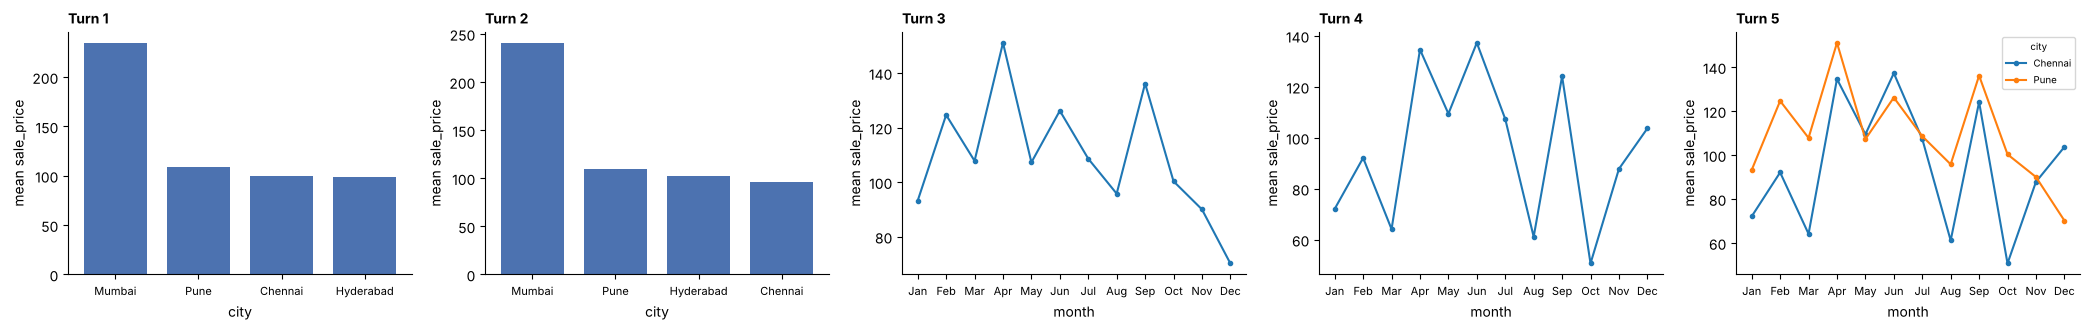

In [23]:
fig, axes = plt.subplots(1, 5, figsize=(21, 3.4))
for ax, s_, i in zip(axes, states, range(1, 6)):
    render_spec(state_to_spec(s_, title=f"Turn {i}"), df, ax=ax)
plt.tight_layout(); plt.show()

### 5.2 More turn types in action

In [24]:
t2, _ = run_dialogue(["average price by city", "only for Pune and Mumbai", "split it by property type", "show the median instead",
                      "as a line chart", "sort them by price"])
t2

,turn,utterance,turn type,transition,echoed interpretation
0,1,average price by city,New query,-,mean(sale_price) by city · filters: none · bar chart
1,2,only for Pune and Mumbai,Refine (add filter),Continue,"mean(sale_price) by city · filters: city = ['Pune', 'Mumbai'] · bar chart"
2,3,split it by property type,Elaborate,Continue,"mean(sale_price) by city / colour = property_type · filters: city = ['Pune',..."
3,4,show the median instead,Change aggregation,Continue,median(sale_price) by city / colour = property_type · filters: city = ['Pune...
4,5,as a line chart,Change view,Continue,median(sale_price) by city / colour = property_type · filters: city = ['Pune...
5,6,sort them by price,Sort (anaphora: 'them' = the bars shown),Continue,median(sale_price) by city / colour = property_type · filters: city = ['Pune...


---
# Topic 6 · Follow-Up Questions and Context Preservation
### 6.1 Follow-ups depend on context
| Phenomenon | Example | Resolution |
|---|---|---|
| **Ellipsis** | *"…and for 2023?"* | missing words are copied from the previous query |
| **Anaphora** | *"Sort them by price."* | *'them'* refers to the cities currently shown |
| **Deixis** (pointing) | *"Why is this one so high?"* + tap | refers to a selected mark (Orko) |

Evizeon's **context transitions** (centering theory) after *"prices in Pune 2024"*:

| Transition | Meaning | Example | Context action |
|---|---|---|---|
| Continue | same focus, more detail | "by number of bedrooms" | keep all, add field |
| Retain | same entities, new angle | "what about rents?" | keep filters, swap measure |
| Shift | new topic | "now show monthly rent by property type" | reset filters and fields |

In [25]:
base = ["average price by city in Pune in 2024"]      # prices in Pune 2024
for follow in ["by bedrooms", "what about rents?", "now show monthly rent by property type", "and for 2023?"]:
    A = parse(base[0]); s0 = build_state(A)
    s1, ops, tr, notes = converse(s0, follow)
    print(f"{follow!r:42s} transition = {tr:8s} ops = {ops}")
    print(f"{'':44s}state: {describe(s1)}")

'by bedrooms'                              transition = Continue ops = ['Elaborate']
                                            state: mean(sale_price) by city / colour = bedrooms · filters: year = 2024, city = Pune · bar chart
'what about rents?'                        transition = Retain   ops = ['Retain (swap measure)']
                                            state: mean(monthly_rent) by city · filters: year = 2024, city = Pune · bar chart
'now show monthly rent by property type'   transition = Shift    ops = ['Shift / reset']
                                            state: mean(monthly_rent) by month / colour = property_type · filters: none · line chart
'and for 2023?'                            transition = Continue ops = ['Refine (replace value)']
                                            state: mean(sale_price) by city · filters: year = 2023, city = Pune · bar chart


### Elliptical follow-ups: why they must inherit context
The slide's MCQ 2: *"show sales by region"* then *"what about last year?"* — a system that treats the second utterance as a **brand-new** query redraws everything. Below, the same chain with and without context carry-over:

In [26]:
def converse_no_context(s, utt, df=df):           # BUG: every utterance is treated as a new, standalone question
    P = parse(utt, df); ns = build_state(P) or s
    if P["measure"] is None: ns = copy.deepcopy(s); ns.filters = {}      # forgets the filters
    return ns

s = build_state(parse("average price by city in 2024"))
s_good, *_ = converse(s, "what about rents?")
s_bad = converse_no_context(s, "what about rents?")
print("With context   :", describe(s_good))
print("Without context:", describe(s_bad), "  <- treated as a brand-new query; year = 2024 silently dropped")

With context   : mean(monthly_rent) by city · filters: year = 2024 · bar chart
Without context: count(monthly_rent) by monthly_rent · filters: none · histogram chart   <- treated as a brand-new query; year = 2024 silently dropped


### 6.2 Numerical 2 · Why context errors compound
A system resolves each follow-up correctly with probability *p = 0.90* and each turn builds on the last: **P(all correct after n turns) = pⁿ**.

(a) 5 turns            : 0.590
(b) 10 turns           : 0.349
(c) p = 0.95, 5 turns  : 0.774
(d) turns for P < 0.5 at p=0.90: n > ln0.5/ln0.9 = 6.58  ->  7 turns
MCQ 6 check: 0.9^4 = 0.6561  (0.73 is 0.9^3; 0.60 wrongly adds error rates 1-4*0.1)


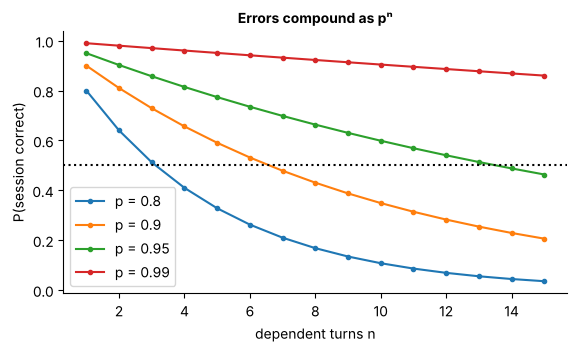

Lesson: ECHO the interpretation every turn so the user catches an error before it spreads.


In [27]:
p = 0.90
print(f"(a) 5 turns            : {p**5:.3f}")
print(f"(b) 10 turns           : {p**10:.3f}")
print(f"(c) p = 0.95, 5 turns  : {0.95**5:.3f}")
n_star = math.log(0.5) / math.log(p)
print(f"(d) turns for P < 0.5 at p=0.90: n > ln0.5/ln0.9 = {n_star:.2f}  ->  {math.floor(n_star) + 1} turns")
print(f"MCQ 6 check: 0.9^4 = {0.9**4:.4f}  (0.73 is 0.9^3; 0.60 wrongly adds error rates 1-4*0.1)")

ns_ = np.arange(1, 16)
plt.figure(figsize=(6.5, 3.4))
for pp in [0.80, 0.90, 0.95, 0.99]: plt.plot(ns_, pp ** ns_, marker="o", ms=3, label=f"p = {pp}")
plt.axhline(.5, color="k", ls=":"); plt.xlabel("dependent turns n"); plt.ylabel("P(session correct)"); plt.legend(); plt.title("Errors compound as pⁿ")
plt.show()
print("Lesson: ECHO the interpretation every turn so the user catches an error before it spreads.")

---
# Topic 7 · Text-to-Chart Generation Using LLMs
### 7.1 Prompting strategies
| Strategy | What you add to the prompt | Helps with |
|---|---|---|
| Zero-shot | Only schema + question | Quick; works for simple charts |
| Few-shot | 2–3 (question, code) examples | Consistent style and output format |
| Schema + samples | Column types and a few rows | Fewer hallucinated columns, correct parsing |
| Plan, then code | "First list fields, aggregation, chart; then code" | Reasoning you can check before running |
| Design rules | Knaflic/Wilke rules as bullet points | Fewer pies, 3D, unlabelled axes |
| Self-repair loop | Execution error + schema sent back | Code that runs; fixes typos in names |

*No strategy guarantees a correct chart: the output still needs validation (Topic 8).*

In [28]:
FEW_SHOT = [("Average rent by city", "df.groupby('city')['monthly_rent'].mean().plot.bar()"),
            ("Distribution of area", "df['area_sqft'].plot.hist(bins=25)")]
DESIGN_RULES = ["Prefer bars and lines; avoid pies with more than 4 slices, 3-D and secondary y-axes.",
                "Sort bars; start bar axes at zero.", "Title states the point; axes carry units."]

def build_prompt(question, df, strategy="zero-shot", error=None):
    parts = [f"You write matplotlib code for a pandas DataFrame named df.\nQuestion: {question}"]
    parts.insert(1, "Columns: " + ", ".join(df.columns))
    if strategy in ("schema+samples", "plan", "design", "few-shot", "repair"):
        parts.insert(2, "Schema:\n" + "\n".join(f"- {c}: {df[c].dtype}" for c in df.columns) + "\nSample rows:\n" + df.head(3).to_csv(index=False))
    if strategy == "few-shot":  parts.insert(1, "Examples:\n" + "\n".join(f"Q: {q}\nCode: {c}" for q, c in FEW_SHOT))
    if strategy == "plan":      parts.append("First list the fields, the aggregation and the chart type. Then write the code.")
    if strategy == "design":    parts.append("Design rules:\n" + "\n".join("- " + r for r in DESIGN_RULES))
    if error:                   parts.append(f"ERROR: {error}\nFix the code. Only use the columns listed above.")
    return "\n\n".join(parts)

lengths = {s: len(build_prompt("Average sale price by city", df, s)) for s in ["zero-shot", "few-shot", "schema+samples", "plan", "design"]}
display(pd.Series(lengths, name="prompt length (characters)").to_frame())
print(build_prompt("Average sale price by city", df, "design")[:900], "...")

,prompt length (characters)
zero-shot,197
few-shot,784
schema+samples,625
plan,706
design,808


You write matplotlib code for a pandas DataFrame named df.
Question: Average sale price by city

Columns: city, year, month, property_type, bedrooms, area_sqft, list_price, sale_price, monthly_rent

Schema:
- city: str
- year: int64
- month: str
- property_type: str
- bedrooms: int64
- area_sqft: float64
- list_price: float64
- sale_price: float64
- monthly_rent: float64
Sample rows:
city,year,month,property_type,bedrooms,area_sqft,list_price,sale_price,monthly_rent
Pune,2025,Feb,Apartment,2,1672.0,176.8,164.2,55700.0
Hyderabad,2022,Nov,Studio,1,385.0,24.9,23.3,7800.0
Chennai,2025,Oct,Studio,1,525.0,40.0,37.6,10400.0


Design rules:
- Prefer bars and lines; avoid pies with more than 4 slices, 3-D and secondary y-axes.
- Sort bars; start bar axes at zero.
- Title states the point; axes carry units. ...


### 7.2 The Generate → Execute → Repair loop (LIDA-style)
1. Generate code or spec · 2. Execute in a sandbox · 3. On error: send **error + schema** back · 4. LLM repairs; retry (max 2–3) · 5. Still failing: **ask the user**.

Our mock LLM makes a typo in a column name on its first attempt, and repairs it when it is shown the error and the schema.

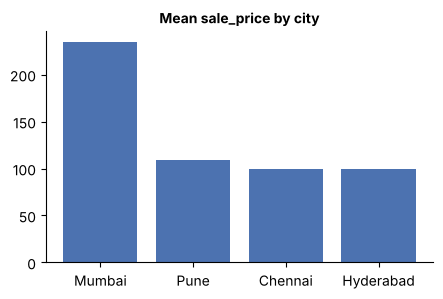

,attempt,result
0,1,KeyError: 'Column not found: sale_prise'
1,2,OK


,attempt,result
0,1,KeyError: 'Column not found: rating'
1,2,ValueError: cannot find a matching column
2,3,ValueError: cannot find a matching column
3,-,still failing -> ASK THE USER


In [29]:
CODE = "fig, ax = plt.subplots(figsize=(5, 3))\nt = df.groupby('city')['{col}'].mean().sort_values(ascending=False)\nax.bar(t.index, t.values, color='#4C72B0')\nax.set_title('Mean {col} by city')"

def mock_llm(prompt):
    if "ERROR:" in prompt:
        m = re.search(r"Column not found: (\w+)", prompt) or re.search(r"KeyError: '(\w+)'", prompt)
        bad = m.group(1) if m else None
        cols = re.search(r"Columns: (.*)", prompt).group(1).split(", ")
        fix = difflib.get_close_matches(bad or "", cols, n=1, cutoff=0.6)
        return CODE.format(col=fix[0]) if fix else "raise ValueError('cannot find a matching column')"
    q = prompt.split("Question:")[1].split("\n")[0].lower()
    if "rating" in q:      return CODE.format(col="rating")                 # hallucinated column
    if "total" in q:       return CODE.format(col="sale_price")             # note: ignores 'total' and computes the MEAN!
    if "sale price" in q:  return CODE.format(col="sale_prise")             # typo
    return CODE.format(col="sale_price")

def execute(code_str, df):
    try:
        exec(code_str, {"df": df, "pd": pd, "np": np, "plt": plt}); return None
    except Exception as e:
        return f"{type(e).__name__}: {e}"

def generate_execute_repair(question, df, llm=mock_llm, max_tries=3, strategy="schema+samples"):
    prompt = build_prompt(question, df, strategy); log = []
    for attempt in range(1, max_tries + 1):
        code_str = llm(prompt); err = execute(code_str, df)
        log.append((attempt, "OK" if err is None else err[:70]))
        if err is None:
            plt.show(); return code_str, log
        plt.close("all")
        prompt = build_prompt(question, df, "repair", error=err)          # send error + schema back
    return None, log + [("-", "still failing -> ASK THE USER")]

code_str, log = generate_execute_repair("Show mean sale price by city", df); display(pd.DataFrame(log, columns=["attempt", "result"]))
code_str, log = generate_execute_repair("Show the average customer rating", df); display(pd.DataFrame(log, columns=["attempt", "result"]))

### Runs ≠ correct
A chart that **runs** can still answer the **wrong question**: the question asked for a *total* but the generated code computes a *mean*. The loop reports success — only validation (or a human) catches it.

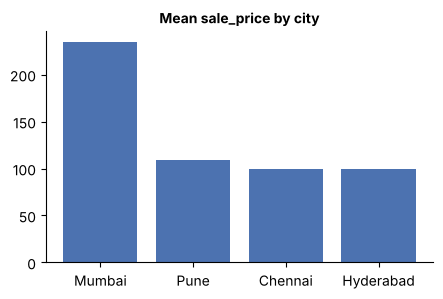

[(1, 'OK')] 
-> loop says OK, but the chart shows MEAN price; the question asked for TOTAL.
Mean : {'Chennai': 100.0, 'Hyderabad': 99.0, 'Mumbai': 234.0, 'Pune': 109.0}
Total: {'Chennai': 41096.0, 'Hyderabad': 42425.0, 'Mumbai': 70016.0, 'Pune': 50330.0}


In [30]:
code_str, log = generate_execute_repair("Show total sale price by city", df)
print(log, "\n-> loop says OK, but the chart shows MEAN price; the question asked for TOTAL.")
print("Mean :", df.groupby('city')['sale_price'].mean().round(0).to_dict())
print("Total:", df.groupby('city')['sale_price'].sum().round(0).to_dict())

### 7.3 NL2Vis systems compared

In [31]:
pd.DataFrame([
    ("NL4DV (2021)",        "Question + CSV",           "Rules + dependency parsing",       "Analytic spec + Vega-Lite"),
    ("Data2Vis (2019)",     "Data rows (no question)",  "Seq2seq translation (LSTM)",       "Vega-Lite spec"),
    ("ncNet / nvBench (2021)", "Question + table",      "Transformer trained on 25k pairs", "Vis query language"),
    ("Chat2VIS (2023)",     "Question + schema",        "LLM prompting (GPT, Codex)",       "Python code"),
    ("LIDA (2023)",         "Dataset (+ optional goal)", "LLM modules + repair",            "Code, any library"),
    ("Copilot / Pulse",     "Question in BI tool",      "LLM + BI semantic model",          "Native chart + narrative"),
], columns=["System", "Input", "Method", "Output"]).set_index("System")

,Input,Method,Output
System,,,
NL4DV (2021),Question + CSV,Rules + dependency parsing,Analytic spec + Vega-Lite
Data2Vis (2019),Data rows (no question),Seq2seq translation (LSTM),Vega-Lite spec
ncNet / nvBench (2021),Question + table,Transformer trained on 25k pairs,Vis query language
Chat2VIS (2023),Question + schema,"LLM prompting (GPT, Codex)",Python code
LIDA (2023),Dataset (+ optional goal),LLM modules + repair,"Code, any library"
Copilot / Pulse,Question in BI tool,LLM + BI semantic model,Native chart + narrative


---
# Topic 8 · LLM-Generated Chart Specifications
### 8.1 Specs, not just code: Vega-Lite
| Spec key | Wilke Ch 2 concept |
|---|---|
| `mark` | graphical element |
| `encoding.x / y / color` | aesthetics (position, colour) |
| `type: nominal / quantitative` | data type → discrete / continuous scale |
| `aggregate`, `filter` | data transformation |

**Specs are safer than code:** no arbitrary code execution; easy to validate, diff and edit. **Code is still used** because it is more flexible (any library, custom styling, complex transforms).
Our renderer above draws a **Vega-Lite-style** subset. Here is a spec an LLM might emit:

{
 "title": "Mean sale price by city, 2024",
 "transform": [
  {
   "filter": {
    "field": "year",
    "equal": 2024
   }
  }
 ],
 "mark": "bar",
 "encoding": {
  "x": {
   "field": "city",
   "type": "nominal",
   "sort": "-y"
  },
  "y": {
   "field": "sale_price",
   "aggregate": "mean",
   "type": "quantitative",
   "title": "mean sale price (\u20b9 lakh)"
  }
 }
}


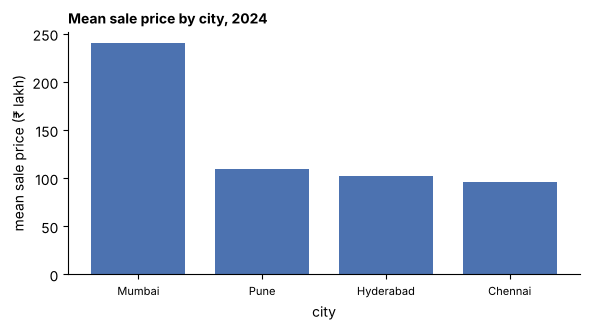

In [32]:
spec_good = {
    "title": "Mean sale price by city, 2024",
    "transform": [{"filter": {"field": "year", "equal": 2024}}],
    "mark": "bar",
    "encoding": {"x": {"field": "city", "type": "nominal", "sort": "-y"},
                 "y": {"field": "sale_price", "aggregate": "mean", "type": "quantitative", "title": "mean sale price (₹ lakh)"}},
}
print(json.dumps(spec_good, indent=1))
render_spec(spec_good, df); plt.tight_layout(); plt.show()

### 8.2 Validating an LLM-generated spec (four checks)
| Check | Catches | Example |
|---|---|---|
| **Schema** | malformed JSON, unknown keys | `"colour"` instead of `"color"` |
| **Field** | hallucinated columns | `"rating"` not in the dataset |
| **Type–channel** | expressiveness violations | quantitative price on shape |
| **Sanity** | wrong aggregation / filter | asked average, spec says sum |

In [33]:
VALID_TOP = {"title", "data", "transform", "mark", "encoding"}
VALID_CH  = {"x", "y", "color", "shape", "size"}
VALID_KEYS = {"field", "type", "aggregate", "sort", "scale", "title", "condition", "value", "bin"}

def validate_spec(spec, df, intent=None):
    problems = []
    hint = lambda k, pool: (" (did you mean '" + difflib.get_close_matches(k, pool, 1)[0] + "'?)") if difflib.get_close_matches(k, pool, 1) else ""
    # 1. schema
    for k in spec:
        if k not in VALID_TOP: problems.append(("1 schema", f"unknown top-level key '{k}'" + hint(k, VALID_TOP)))
    enc = spec.get("encoding", {})
    for ch, e in enc.items():
        if ch not in VALID_CH: problems.append(("1 schema", f"unknown channel '{ch}'" + hint(ch, VALID_CH))); continue
        for k in e:
            if k not in VALID_KEYS: problems.append(("1 schema", f"unknown key '{k}' in channel {ch}" + hint(k, VALID_KEYS)))
    # 2. field
    used = [e["field"] for e in enc.values() if isinstance(e, dict) and "field" in e]
    used += [t["filter"]["field"] for t in spec.get("transform", []) if "filter" in t]
    for f in used:
        if f not in df.columns: problems.append(("2 field", f"field '{f}' is not in the dataset" + hint(f, list(df.columns))))
    # 3. type-channel (expressiveness)
    for ch, e in enc.items():
        if not isinstance(e, dict): continue
        if ch == "shape" and e.get("type") == "quantitative": problems.append(("3 type-channel", f"quantitative '{e.get('field')}' on shape: not expressive"))
        if ch == "size"  and e.get("type") == "nominal":      problems.append(("3 type-channel", f"nominal '{e.get('field')}' on size implies a fake order"))
    # 4. sanity vs the user's intent
    if intent:
        for e in enc.values():
            if isinstance(e, dict) and "aggregate" in e and intent.get("aggregate") and e["aggregate"] != intent["aggregate"] and e["aggregate"] != "count":
                problems.append(("4 sanity", f"asked '{intent['aggregate']}' but spec says '{e['aggregate']}'"))
        have = {t["filter"]["field"]: ([t["filter"]["equal"]] if "equal" in t["filter"] else t["filter"].get("oneOf")) for t in spec.get("transform", []) if "filter" in t}
        for f, v in intent.get("filters", {}).items():
            if have.get(f) != v: problems.append(("4 sanity", f"asked filter {f}={v} but spec has {have.get(f)}"))
    return pd.DataFrame(problems, columns=["check", "problem"]) if problems else pd.DataFrame([("all", "OK")], columns=["check", "problem"])

intent = {"aggregate": "mean", "filters": {"year": [2024]}}
bad_specs = {
    "S1 colour typo":        {**copy.deepcopy(spec_good), "encoding": {**spec_good["encoding"], "colour": {"field": "property_type", "type": "nominal"}}},
    "S2 hallucinated field": {**copy.deepcopy(spec_good), "encoding": {"x": {"field": "city", "type": "nominal"}, "y": {"field": "rating", "aggregate": "mean", "type": "quantitative"}}},
    "S3 price on shape":     {**copy.deepcopy(spec_good), "encoding": {**spec_good["encoding"], "shape": {"field": "sale_price", "type": "quantitative"}}},
    "S4 sum, no 2024":       {"title": "x", "mark": "bar", "encoding": {"x": {"field": "city", "type": "nominal"}, "y": {"field": "sale_price", "aggregate": "sum", "type": "quantitative"}}},
}
print("GOOD spec:"); display(validate_spec(spec_good, df, intent))
for name, sp in bad_specs.items():
    print(name); display(validate_spec(sp, df, intent))
print("MCQ 4 check: \"shape\" is a valid key and 'sale_price' exists, so checks 1-2 pass; check 3 (type-channel) stops it.")

GOOD spec:


,check,problem
0,all,OK


S1 colour typo


,check,problem
0,1 schema,unknown channel 'colour' (did you mean 'color'?)


S2 hallucinated field


,check,problem
0,2 field,field 'rating' is not in the dataset


S3 price on shape


,check,problem
0,3 type-channel,quantitative 'sale_price' on shape: not expressive


S4 sum, no 2024


,check,problem
0,4 sanity,asked 'mean' but spec says 'sum'
1,4 sanity,asked filter year=[2024] but spec has None


MCQ 4 check: "shape" is a valid key and 'sale_price' exists, so checks 1-2 pass; check 3 (type-channel) stops it.


### Numerical 3 · Evaluating NL2Vis outputs: exact match vs execution accuracy
* **Exact match (EM):** every component equals the reference spec. · **Execution accuracy (EA):** the plotted *data values* equal the reference values.
* **Component accuracy:** share of queries with that part correct.

In [34]:
T, F = True, False
ev = pd.DataFrame({"chart": [T, T, F, T, T], "x": [T]*5, "y": [T]*5, "aggregation": [T, F, T, T, T], "filter": [T, T, T, F, T],
                   "values_right": [T, F, T, F, T]}, index=["Q1", "Q2", "Q3", "Q4", "Q5"])
ev["exact_match"] = ev[["chart", "x", "y", "aggregation", "filter"]].all(axis=1)
display(ev)
print("Component accuracy:", ev[["chart", "x", "y", "aggregation", "filter"]].mean().to_dict())
print(f"Exact match        = {ev.exact_match.mean():.2f}")
print(f"Execution accuracy = {ev.values_right.mean():.2f}")
print("Q3 has the right numbers but the wrong chart -> counts for EA, not EM.")
print(f"\nMCQ 7 check: 7 of 10 correct values, 2 of those wrong chart -> EA = {7/10}, EM = {(7-2)/10}")

,chart,x,y,aggregation,filter,values_right,exact_match
Q1,True,True,True,True,True,True,True
Q2,True,True,True,False,True,False,False
Q3,False,True,True,True,True,True,False
Q4,True,True,True,True,False,False,False
Q5,True,True,True,True,True,True,True


Component accuracy: {'chart': 0.8, 'x': 1.0, 'y': 1.0, 'aggregation': 0.8, 'filter': 0.8}
Exact match        = 0.40
Execution accuracy = 0.60
Q3 has the right numbers but the wrong chart -> counts for EA, not EM.

MCQ 7 check: 7 of 10 correct values, 2 of those wrong chart -> EA = 0.7, EM = 0.5


---
# Topic 9 · Conversational Chart Editing
### 9.1 Editing charts by talking to them: utterance → **spec patch**
| Utterance | Spec change (patch) | Design reason |
|---|---|---|
| "sort highest first" | `x.sort = "-y"` | ordered bars are easier to compare |
| "make the bars horizontal" | swap x and y | long city names fit on the y-axis |
| "highlight Mumbai in orange" | `color = condition(city == Mumbai)` | focus attention (Knaflic Ch 4) |
| "use a log scale" | `y.scale.type = "log"` | values span orders of magnitude |
| "add a title that says the point" | `title = assertion text` | title conveys the point (Wilke Ch 22) |
| "start the axis at zero" | `y.scale.zero = true` | bars must start at zero (Wilke Ch 17) |

**Good editing = minimal change:** alter only the requested property and keep everything else stable.

In [35]:
def _cat_val(spec):
    e = spec["encoding"]; return ("y", "x") if is_horizontal(spec) else ("x", "y")

def edit_sort(spec, direction="-y"):
    s = copy.deepcopy(spec); c, v = _cat_val(s); s["encoding"][c]["sort"] = direction; return s
def edit_horizontal(spec):
    s = copy.deepcopy(spec); s["encoding"]["x"], s["encoding"]["y"] = s["encoding"]["y"], s["encoding"]["x"]; return s
def edit_highlight(spec, value, colour=ACCENT):
    s = copy.deepcopy(spec); c, v = _cat_val(s)
    s["encoding"]["color"] = {"condition": {"field": s["encoding"][c]["field"], "equal": value, "value": colour}, "value": GREY}; return s
def edit_log(spec):
    s = copy.deepcopy(spec); c, v = _cat_val(s); s["encoding"][v]["scale"] = {"type": "log"}; return s
def edit_title(spec, text):
    s = copy.deepcopy(spec); s["title"] = text; return s
def edit_zero(spec):
    s = copy.deepcopy(spec); c, v = _cat_val(s); s["encoding"][v].setdefault("scale", {})["zero"] = True; return s

def flatten(d, prefix=""):
    out = {}
    for k, v in d.items():
        p = f"{prefix}.{k}" if prefix else k
        if isinstance(v, dict): out.update(flatten(v, p))
        else: out[p] = json.dumps(v)
    return out

def spec_diff(a, b):
    fa, fb = flatten(a), flatten(b)
    return sorted(k for k in set(fa) | set(fb) if fa.get(k) != fb.get(k))

base = {"title": "Mean sale price by city", "transform": [], "mark": "bar",
        "encoding": {"x": {"field": "city", "type": "nominal"}, "y": {"field": "sale_price", "aggregate": "mean", "type": "quantitative", "title": "mean sale price (₹ lakh)"}}}
edits = [("sort highest first", edit_sort), ("make the bars horizontal", edit_horizontal), ("highlight Mumbai in orange", lambda s: edit_highlight(s, "Mumbai")),
         ("use a log scale", edit_log), ("start the axis at zero", edit_zero), ("add a title that says the point", lambda s: edit_title(s, "Mumbai homes sell for far more than the other cities"))]
rows = []
for name, fn in edits:
    new = fn(base); rows.append((name, ", ".join(spec_diff(base, new))))
pd.DataFrame(rows, columns=["utterance", "spec paths that changed (should be minimal)"])

,utterance,spec paths that changed (should be minimal)
0,sort highest first,encoding.x.sort
1,make the bars horizontal,"encoding.x.aggregate, encoding.x.field, encoding.x.title, encoding.x.type, e..."
2,highlight Mumbai in orange,"encoding.color.condition.equal, encoding.color.condition.field, encoding.col..."
3,use a log scale,encoding.y.scale.type
4,start the axis at zero,encoding.y.scale.zero
5,add a title that says the point,title


### 9.2 Five edits, one better chart
Knaflic Ch 7: *tell the story in steps, each building on the last.*  **1 Show the data → 2 Sort for comparison → 3 Horizontal for long labels → 4 Highlight the focus city → 5 Assertion title.**

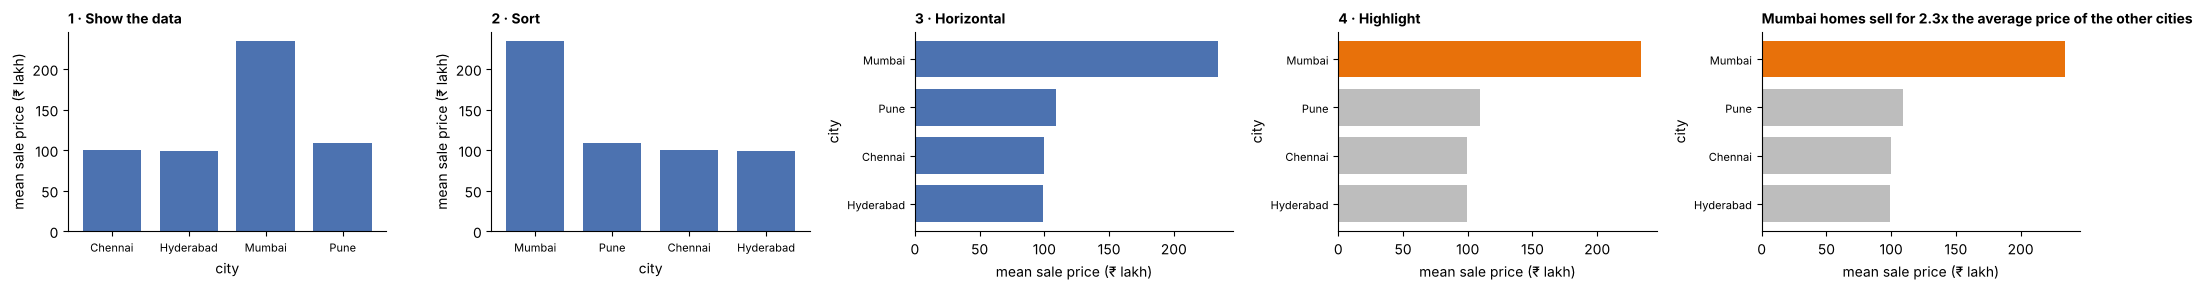

Assertion title: Mumbai homes sell for 2.3x the average price of the other cities


In [36]:
def assertion_title(df):
    g = df.groupby("city")["sale_price"].mean(); top = g.idxmax()
    ratio = g[top] / g.drop(top).mean()
    return f"{top} homes sell for {ratio:.1f}x the average price of the other cities"

s1 = base
s2 = edit_sort(s1)
s3 = edit_horizontal(s2)
s4 = edit_highlight(s3, "Mumbai")
s5 = edit_title(s4, assertion_title(df))
s1 = edit_title(s1, "1 · Show the data"); s2 = edit_title(s2, "2 · Sort"); s3 = edit_title(s3, "3 · Horizontal"); s4 = edit_title(s4, "4 · Highlight")
show_specs([s1, s2, s3, s4, s5], df, ncols=5, w=4.2, h=3.0)
print("Assertion title:", assertion_title(df))

### 9.3 What an LLM should write: titles and labels (Wilke Ch 22, Knaflic Ch 7)
* Every figure needs a title that **states its point** — not *"This figure shows…"*.
* Axis and legend titles state the **variable and its units**.
* Omit titles only when labels are self-explanatory; don't over-label (*"time (years AD)"* is ugly).

> *"The job of the title is to accurately convey to the reader what the figure is about, what point it makes."* — Wilke, Ch 22

In [37]:
def lint_chart(spec):
    issues = []
    t = spec.get("title", "").strip().lower()
    if not t: issues.append("no title")
    if re.match(r"^(this|the) (chart|figure|graph|plot) (shows|displays|presents)", t): issues.append("title describes the chart instead of asserting the point")
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if e.get("type") == "quantitative" and "title" not in e: issues.append(f"{ch}-axis has no title with units")
    return issues or ["OK"]

weak = {"title": "This chart shows sale price by city", "mark": "bar",
        "encoding": {"x": {"field": "city", "type": "nominal"}, "y": {"field": "sale_price", "aggregate": "mean", "type": "quantitative"}}}
print("Weak  :", lint_chart(weak))
print("Fixed :", lint_chart(s5))
print("MCQ 8 check: assert the point in the title, add y-axis units, do not add 'time (years AD)'.")

Weak  : ['title describes the chart instead of asserting the point', 'y-axis has no title with units']
Fixed : ['OK']
MCQ 8 check: assert the point in the title, add y-axis units, do not add 'time (years AD)'.


---
# Topic 10 · Benefits and Failure Modes of LLM-Generated Visualizations
### 10.1 Benefits
**Low barrier** (no chart grammar) · **Speed** · **Flexible language** (paraphrases, typos, vague requests) · **Iterative** (refine through conversation) · **Explains itself** (captions, summaries, comments) · **Any library**.

### 10.2 Failure modes — each demonstrated

In [38]:
pd.DataFrame([
    ("Hallucinated field",            "plots 'rating' that does not exist",        "crashes, or worse, plots invented data"),
    ("Wrong aggregation / filter",    "sum instead of average; drops 2024",         "runs fine, looks plausible, wrong answer"),
    ("Wrong chart for the task",      "line across categories; 12-slice pie",       "misleads about order or parts"),
    ("Misleading design",             "truncated axis, dual axes",                  "exaggerates differences (Wilke Ch 17)"),
    ("Context drift",                 "follow-up silently drops a filter",          "user trusts an outdated view"),
    ("Over-confident narrative",      "caption claims a cause",                     "correlation presented as causation"),
], columns=["Failure", "Example", "Why it is dangerous"]).set_index("Failure")

,Example,Why it is dangerous
Failure,,
Hallucinated field,plots 'rating' that does not exist,"crashes, or worse, plots invented data"
Wrong aggregation / filter,sum instead of average; drops 2024,"runs fine, looks plausible, wrong answer"
Wrong chart for the task,line across categories; 12-slice pie,misleads about order or parts
Misleading design,"truncated axis, dual axes",exaggerates differences (Wilke Ch 17)
Context drift,follow-up silently drops a filter,user trusts an outdated view
Over-confident narrative,caption claims a cause,correlation presented as causation


1 Hallucinated field


,check,problem
0,2 field,field 'rating' is not in the dataset


2 Wrong aggregation / filter


,check,problem
0,4 sanity,asked 'mean' but spec says 'sum'
1,4 sanity,asked filter year=[2024] but spec has None


   reference (mean, 2024): {'Chennai': 96.0, 'Hyderabad': 102.0, 'Mumbai': 240.0, 'Pune': 110.0}
   LLM output (sum, all)  : {'Chennai': 41096.0, 'Hyderabad': 42425.0, 'Mumbai': 70016.0, 'Pune': 50330.0}


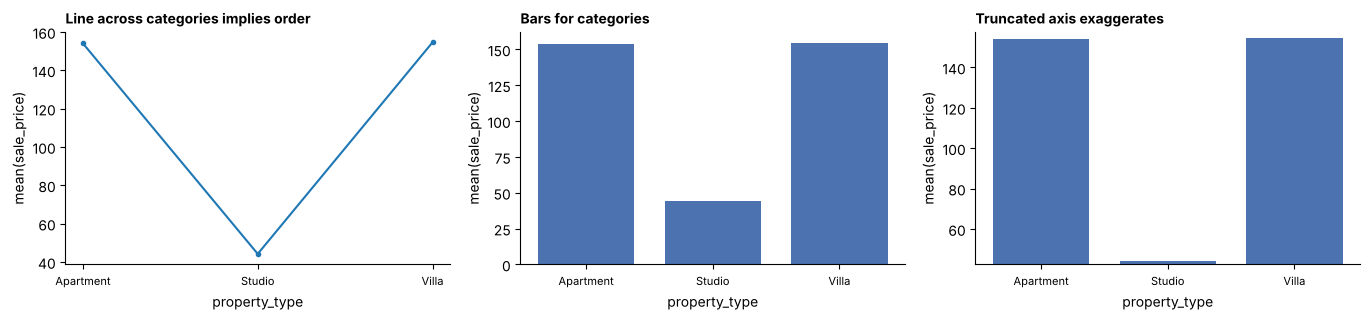

In [39]:
# 1 Hallucinated field -> the field check catches it
print("1 Hallucinated field"); display(validate_spec(bad_specs["S2 hallucinated field"], df))

# 2 Wrong aggregation / filter -> runs fine, wrong numbers (caught by the sanity check or an EA test)
print("2 Wrong aggregation / filter"); display(validate_spec(bad_specs["S4 sum, no 2024"], df, intent))
ref = compute(spec_good, df)
wrong = compute({**spec_good, "transform": [], "encoding": {**spec_good["encoding"], "y": {**spec_good["encoding"]["y"], "aggregate": "sum"}}}, df)
print("   reference (mean, 2024):", ref.set_index("city")["value"].round(0).to_dict())
print("   LLM output (sum, all)  :", wrong.set_index("city")["value"].round(0).to_dict())

# 3 Wrong chart for the task + 4 Misleading design
by_type = {"title": "Mean sale price by property type", "mark": "line",
           "encoding": {"x": {"field": "property_type", "type": "nominal"}, "y": {"field": "sale_price", "aggregate": "mean", "type": "quantitative"}}}
bar_ok = {**by_type, "mark": "bar", "title": "Bars for categories"}
trunc  = {**bar_ok, "title": "Truncated axis exaggerates", "encoding": {**by_type["encoding"], "y": {**by_type["encoding"]["y"], "scale": {"zero": False}}}}
by_type["title"] = "Line across categories implies order"
show_specs([by_type, bar_ok, trunc], df)

In [40]:
# 5 Context drift (see Topic 6): the buggy follow-up lost year = 2024
s = build_state(parse("average price by city in 2024"))
print("5 Context drift  good:", describe(converse(s, "what about rents?")[0]))
print("                 bug :", describe(converse_no_context(s, "what about rents?")))

# 6 Over-confident narrative: correlation is not causation
r_all = df[["area_sqft", "sale_price"]].corr().iloc[0, 1]
within = df.groupby("city").apply(lambda g: g["area_sqft"].corr(g["sale_price"])).round(2).to_dict()
print(f"\n6 Over-confident narrative. r(area, price) overall = {r_all:.2f}; within each city = {within}")
print("   Bad caption : 'Larger flats CAUSE higher prices.'")
print("   Better      : 'Larger flats tend to have higher prices (r = %.2f overall); city differences inflate the pooled figure.'" % r_all)

5 Context drift  good: mean(monthly_rent) by city · filters: year = 2024 · bar chart
                 bug : count(monthly_rent) by monthly_rent · filters: none · histogram chart

6 Over-confident narrative. r(area, price) overall = 0.73; within each city = {'Chennai': 0.96, 'Hyderabad': 0.96, 'Mumbai': 0.96, 'Pune': 0.96}
   Bad caption : 'Larger flats CAUSE higher prices.'
   Better      : 'Larger flats tend to have higher prices (r = 0.73 overall); city differences inflate the pooled figure.'


### 10.3 Locating the failure: Munzner's nested model
Four nested levels: **domain → abstraction → idiom → algorithm**. *"Choosing the wrong block at an upstream level inevitably cascades to all downstream levels."* **Debug from the top: right question before right code.**

LLM-specific: the most *visible* errors are at the algorithm level (code crashes), but the **costliest** are at the **abstraction** level (wrong task, wrong field) because they produce charts that **look right**.

In [41]:
LEVELS = ["domain", "abstraction", "idiom", "algorithm"]
incidents = pd.DataFrame([
    ("KeyError: column 'rating' not found (code crashed)",                "Hallucinated field",        "algorithm",   "obvious"),
    ("Chart shows SUM when the user asked for AVERAGE",                   "Wrong aggregation / filter", "abstraction", "hidden - looks right"),
    ("Follow-up silently dropped year = 2024",                            "Context drift",             "abstraction", "hidden - looks right"),
    ("12-slice pie for a part-to-whole question",                         "Wrong chart for the task",  "idiom",       "visible to a trained eye"),
    ("Bars with a truncated y-axis",                                      "Misleading design",         "idiom",       "visible to a trained eye"),
    ("Tool does not know finance defines 'revenue' net of incentives",    "(no data/task error)",      "domain",      "hidden - needs the human"),
], columns=["incident", "failure mode", "nested level", "how visible"])
incidents.sort_values("nested level", key=lambda s: s.map(LEVELS.index))

,incident,failure mode,nested level,how visible
5,Tool does not know finance defines 'revenue' net of incentives,(no data/task error),domain,hidden - needs the human
1,Chart shows SUM when the user asked for AVERAGE,Wrong aggregation / filter,abstraction,hidden - looks right
2,Follow-up silently dropped year = 2024,Context drift,abstraction,hidden - looks right
3,12-slice pie for a part-to-whole question,Wrong chart for the task,idiom,visible to a trained eye
4,Bars with a truncated y-axis,Misleading design,idiom,visible to a trained eye
0,KeyError: column 'rating' not found (code crashed),Hallucinated field,algorithm,obvious


### 10.4 Mitigations: keeping humans in control
1. **Echo the interpretation** · 2. **Make choices editable** (widgets) · 3. **Validate before showing** · 4. **Keep the spec/code** (reproducible, auditable — Wilke Ch 28) · 5. **Constrain the design** (rules in the prompt) · 6. **Human review for decisions** — *never ship an unchecked chart to a report*.

All six in one small pipeline:

In [42]:
import tempfile, os
LOG = os.path.join(tempfile.gettempdir(), "nl2vis_spec_log.jsonl")

def safe_pipeline(query, df=df, intent_checks=True):
    A = parse(query, df); s = build_state(A)
    if s is None:
        print(f"Q: {query!r}\n   -> not understood. ASK THE USER (no guessing).\n"); return
    spec = state_to_spec(s)
    print(f"Q: {query!r}")
    print("   1 Echo      :", describe(s))
    print("   2 Editable  :", [f"{a['word']}: {a['candidates']}" for a in A["ambiguities"]] or "no open choices")
    intent = {"aggregate": A["aggregate"], "filters": A["filters"]}
    v = validate_spec(spec, df, intent if intent_checks else None)
    print("   3 Validate  :", "all four checks pass" if v.iloc[0, 0] == "all" else v.to_dict("records"))
    with open(LOG, "a") as f: f.write(json.dumps({"query": query, "spec": spec}) + "\n")
    print("   4 Spec kept :", LOG.split(os.sep)[-1])
    print("   5 Design    :", lint_chart(spec))
    print("   6 Human     : REVIEW REQUIRED before this goes into a report\n")
    return spec

for q in ["average sale price by city in 2024", "show price by property type", "typical value of homes per town"]:
    safe_pipeline(q)

Q: 'average sale price by city in 2024'
   1 Echo      : mean(sale_price) by city · filters: year = 2024 · bar chart
   2 Editable  : no open choices
   3 Validate  : all four checks pass
   4 Spec kept : nl2vis_spec_log.jsonl
   5 Design    : ['OK']
   6 Human     : REVIEW REQUIRED before this goes into a report

Q: 'show price by property type'
   1 Echo      : mean(sale_price) by property_type · filters: none · bar chart
   2 Editable  : ["price: ['sale_price', 'list_price']", "(none stated): ['mean', 'sum']"]
   3 Validate  : all four checks pass
   4 Spec kept : nl2vis_spec_log.jsonl
   5 Design    : ['OK']
   6 Human     : REVIEW REQUIRED before this goes into a report

Q: 'typical value of homes per town'
   -> not understood. ASK THE USER (no guessing).



---
# Summary
| Topic | Take-away |
|---|---|
| NL2Vis | question + schema → spec → chart + explanation |
| Abstraction | map **many words to few abstract tasks** (Munzner Ch 3) |
| Semantic parsing | attributes, values, aggregation, intent; **handle ambiguity** (default+echo · widget · clarify) |
| Conversational systems | the **dialogue state** turns single queries into analysis; make the answer salient |
| Multi-turn & context | refine, elaborate, shift; ellipsis/anaphora; **errors compound as pⁿ** |
| LLM text-to-chart | prompt with schema + rules; **generate → run → repair**; runs ≠ correct |
| Specs & editing | Vega-Lite specs are **checkable**; edits are **small patches**; titles assert the point |
| Failures & fixes | validate, echo, keep humans in control; debug from the top of the **nested model** |

**References:** Wilke *Fundamentals of Data Visualization* (Ch 2, 5, 22) · Knaflic *Storytelling with Data* (Ch 2, 4, 7) · Ware *Information Visualization* (Ch 5, 12) · Munzner *Visualization Analysis and Design* (Ch 1–4) ·
Narechania et al. 2021 (NL4DV) · Dibia & Demiralp 2019 · Luo et al. 2021 (nvBench) · Setlur et al. 2016 (Eviza) · Hoque et al. 2018 (Evizeon) · Srinivasan & Stasko 2018 (Orko) · Gao et al. 2015 (DataTone) ·
Maddigan & Susnjak 2023 (Chat2VIS) · Dibia 2023 (LIDA) · Wang et al. 2024 (Data Formulator) · Satyanarayan et al. 2017 (Vega-Lite).